# OPERA Workshop — Day 3 Applied Challenge
---
## FACILITATOR ANSWER KEY

**Content creator:** Babette C. Tchonang · **Content coordinator:** Arielle Stella Imbol

*OPERA Capacity Development, led jointly by GGOSSS and ICMPA - UNESCO CHAIR. Financed by the European Union, implemented by Mercator Ocean International within the Ocean Prediction Decade Collaborative Centre.*

---

> ###  Do not distribute to participants
> This notebook contains worked solutions to all three scenario cards. Groups must reach these themselves. Use it to know what a good answer looks like, to recognise a group heading somewhere unexpected, and to have a figure ready if one runs out of time.

---

### How to use it

| | |
|---|---|
| **Before 14:15** | Read your own group's section. Run the cells so the figures are ready. |
| **14:15–15:30** | Facilitate, do not direct. Use the *what to probe* prompts. |
| **15:45–16:30** | Use *what a strong briefing contains* to give commentary. |

**The three scenarios are not equivalent, and that is intentional.** Each area's data points to a different mechanism, so each group reaches a different conclusion using the same method. That contrast is the closing plenary.

| Area | Scenario | The finding they should reach |
|---|---|---|
| **1** Mauritania / Senegal | Upwelling monitoring, fisheries | 2023 — the upwelling season failed for seven consecutive months |
| **2** Gulf of Guinea | Coastal flood risk calendar | Two distinct risk windows, and compound events becoming more frequent |
| **3** Agulhas | Eddy-driven risk, aquaculture | Sea level is driven by rings, not by heat — the weakest SST link of the three |

---

### The four things every briefing must contain

| | |
|---|---|
| **1** | One figure, labelled well enough to stand alone |
| **2** | One number with its uncertainty — a trend with a p-value, a count with its baseline |
| **3** | One clear statement of what the audience should do |
| **4** | One honest limitation |

**Point four is not optional, and it is the one groups skip.** Ask for it directly if it is missing.

---


---

##  Section 0 — Setup

*Run before 14:15 so the figures exist when a group needs one.*

---


In [1]:
# ============================================================
# STEP 0.1 — MOUNT, PACKAGES, CONFIG
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os, importlib, subprocess, sys
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

DATA_DIR   = '/content/drive/MyDrive/OPERA_Workshop_Data/data'
OUTPUT_DIR = '/content/drive/MyDrive/OPERA_Workshop_Data/output/AnswerKey'
os.makedirs(OUTPUT_DIR, exist_ok=True)

for imp, pip_name in [('xarray','xarray'), ('scipy','scipy'), ('cartopy','cartopy'),
                      ('h5netcdf','h5netcdf'), ('dask','dask'), ('netCDF4','netCDF4')]:
    try:
        importlib.import_module(imp)
    except ImportError:
        print(f'   installing {pip_name}...')
        subprocess.run([sys.executable,'-m','pip','install',pip_name,'-q'],
                       capture_output=True)
print('==> Environment ready')
print(f'   Data   : {DATA_DIR}')
print(f'   Output : {OUTPUT_DIR}')


Mounted at /content/drive
   installing cartopy...
   installing netCDF4...
==> Environment ready
   Data   : /content/drive/MyDrive/OPERA_Workshop_Data/data
   Output : /content/drive/MyDrive/OPERA_Workshop_Data/output/AnswerKey


In [2]:
# ============================================================
# STEP 0.2 — AREAS AND LOADERS
# ============================================================
import os, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


ZONES = {
    '1': dict(name='Mauritania / Senegal', short='Mauritania', prefix='MRS',
              lon=(-21.0,-15.0), lat=(14.0,25.0), hemisphere='N', cool='JJA',
              scenario='Upwelling monitoring and fisheries advisory',
              audience='CRODT, Dakar  /  IMROP, Nouadhibou', colour='#c0392b'),
    '2': dict(name='Gulf of Guinea', short='Gulf of Guinea', prefix='GOG',
              lon=(5.0,15.0), lat=(-5.0,5.0), hemisphere='N', cool='JJA',
              scenario='Coastal flood risk calendar',
              audience='Civil Protection Agency, Cotonou', colour='#27ae60'),
    '3': dict(name='Agulhas', short='Agulhas', prefix='AGU',
              lon=(15.0,30.0), lat=(-38.0,-30.0), hemisphere='S', cool='DJF',
              scenario='Eddy-driven coastal risk for aquaculture',
              audience='A national fisheries and oceans agency', colour='#2471a3'),
}
DATE_START, DATE_END = '2010-01-01', '2023-12-31'
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']


def zone_files(p):
    return dict(SST=os.path.join(DATA_DIR,f'{p}_SST_reanalysis.nc'),
                SSH=os.path.join(DATA_DIR,f'{p}_SSH_altimetry.nc'),
                CURR=os.path.join(DATA_DIR,f'{p}_currents.nc'),
                WIND=os.path.join(DATA_DIR,f'{p}_wind_monthly.nc'))

def normalise(ds):
    if 'valid_time' in ds.dims and 'time' not in ds.dims:
        ds = ds.rename({'valid_time':'time'})
    return ds.drop_vars(['number','expver'], errors='ignore')

def open_product(kind, prefix):
    ydir = os.path.join(DATA_DIR, f'{prefix}_daily_years')
    ch = sorted(glob.glob(os.path.join(ydir, f'{prefix}_{kind}_*.nc')))
    if ch:
        return normalise(xr.open_mfdataset(ch, combine='by_coords',
                                           chunks={'time':90}, engine='h5netcdf'))
    s = zone_files(prefix)[kind]
    if os.path.exists(s):
        return normalise(xr.open_dataset(s, chunks={'time':90}, engine='h5netcdf'))
    raise FileNotFoundError(f'{kind} for {prefix}')

def surface(da):
    if 'depth' in da.dims: da = da.isel(depth=0)
    return da.squeeze(drop=True)

def clip_to(da, Z):
    return da.sel(latitude=slice(*Z['lat']), longitude=slice(*Z['lon']))


def area_series(kind, var, Z):
    """Daily area-mean series for one variable."""
    ds = open_product(kind, Z['prefix'])
    da = clip_to(ds[var], Z)
    if kind == 'SST':
        da = da - 273.15
    s = da.mean(['latitude','longitude']).to_series()
    ds.close()
    return s


def clim_and_threshold(series, window=11, pctile=90):
    """Hobday: pool +/-5 days about each day of year, across all years."""
    doy = np.asarray(series.index.dayofyear); half = window//2
    clim, thr = {}, {}
    for d in range(1, 367):
        offs = [((d-1+k) % 366)+1 for k in range(-half, half+1)]
        pool = series.values[np.isin(doy, offs)]
        clim[d] = float(np.nanmean(pool)) if len(pool) else np.nan
        thr[d]  = float(np.nanpercentile(pool, pctile)) if len(pool) else np.nan
    return (pd.Series(clim).interpolate().bfill().ffill(),
            pd.Series(thr).interpolate().bfill().ffill())


def detect_mhw(daily, clim_line, p90_line, min_days=5, max_gap=2):
    above = (daily > p90_line).values
    d = np.diff(np.concatenate(([0], above.view(np.int8), [0])))
    st, en = np.where(d==1)[0], np.where(d==-1)[0]-1
    joined=[]
    for a,b in zip(st,en):
        if joined and a-joined[-1][1] <= max_gap+1: joined[-1]=(joined[-1][0],b)
        else: joined.append((a,b))
    ev_idx=[(a,b) for a,b in joined if (b-a+1)>=min_days]
    rec=[]
    for a,b in ev_idx:
        e = daily.iloc[a:b+1]-clim_line.iloc[a:b+1]
        rec.append(dict(start=daily.index[a], end=daily.index[b],
                        duration=b-a+1, i_max=float(e.max()),
                        i_mean=float(e.mean()), i_cum=float(e.sum())))
    return pd.DataFrame(rec), ev_idx


def trend_adj(series):
    """Slope per year, raw p, and p corrected for lag-1 autocorrelation."""
    t = (series.index - series.index[0]).days/365.25
    r = stats.linregress(t, series.values)
    res = series.values - (r.intercept + r.slope*t)
    r1 = np.corrcoef(res[:-1], res[1:])[0,1] if len(res)>2 else 0.0
    n_eff = len(res)*(1-r1)/(1+r1) if abs(r1)<1 else len(res)
    p_adj = 2*(1-stats.t.cdf(abs(r.slope/r.stderr), df=max(n_eff-2,1)))
    return r.slope, r.pvalue, p_adj


def anomalies(s):
    return s - s.groupby(s.index.month).transform('mean')


print('==> Helpers ready:')
print('    area_series, clim_and_threshold, detect_mhw, trend_adj, anomalies')


==> Helpers ready:
    area_series, clim_and_threshold, detect_mhw, trend_adj, anomalies


---
---

#  Scenario 1 — Mauritania / Senegal

**Audience:** CRODT, Dakar and IMROP, Nouadhibou
**Brief:** the upwelling season has become harder to predict; the agency needs an evidence base.

---

## What a strong briefing contains

| | |
|---|---|
| **The mechanism** | 2023 was not simply warm — the upwelling season did not arrive |
| **The evidence** | seven consecutive compound months, April to October, in the season when cooling should be strongest |
| **The number** | 206 days above the marine heatwave threshold in 2023, 56% of the year |
| **The contrast** | nothing comparable in the previous twelve years |
| **The limitation** | 14-year baseline where the standard is 30, and it includes the warm years, so the count is conservative |

## What to probe

- *"You say 2023 was unusual. Unusual compared with what baseline — and does that baseline include 2023?"*
- *"Your compound months run April to October. What normally happens in those months here?"*
- *"If you had to give CRODT one number, which is it and why?"*
- *"What would you need to confirm the upwelling failed rather than the water simply being warm?"*

## Where groups go wrong

**Reporting warmth instead of failure.** "2023 was warm" is weaker than "the cooling did not happen." Push them toward the seasonal framing.

**Forgetting the wind.** They have ERA5. If the upwelling failed, the alongshore wind is the first place to look, and checking it turns a description into an explanation.

---


Mauritania / Senegal — Upwelling monitoring and fisheries advisory
Audience: CRODT, Dakar  /  IMROP, Nouadhibou

Loading SST and SSH...
Done.

   Marine heatwaves detected : 19
   Worst year                : 2023, 206 days (56% of the year)
   Compound months           : 10
   In 2023 alone              : 8



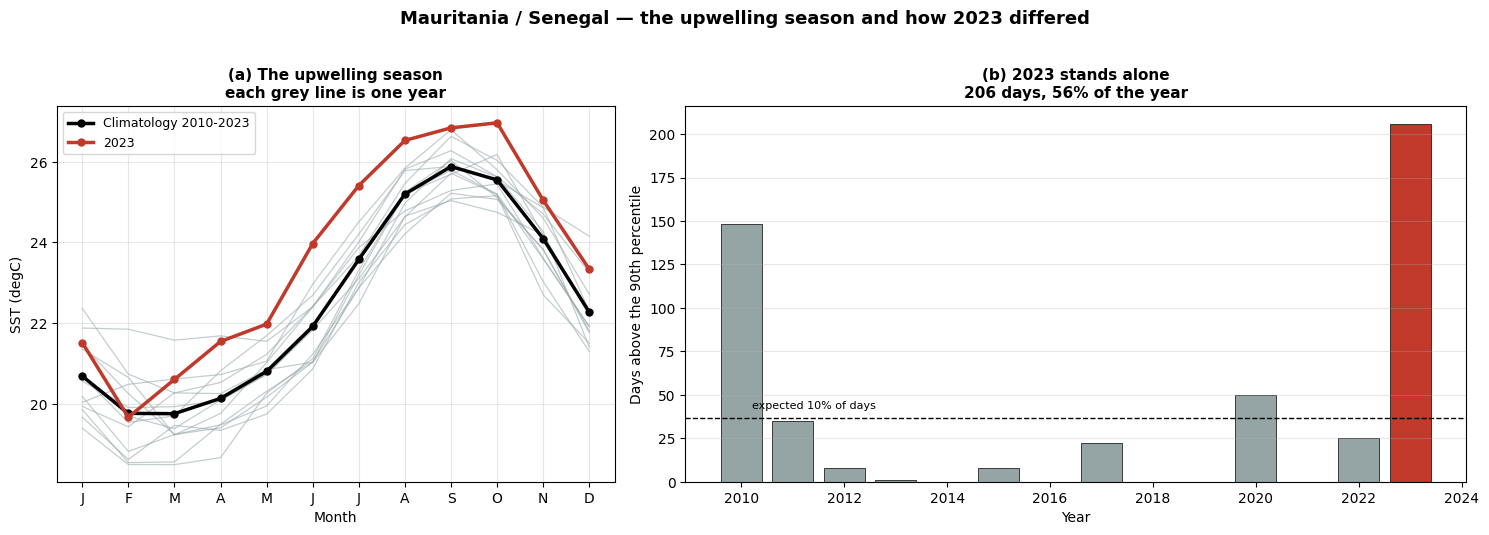

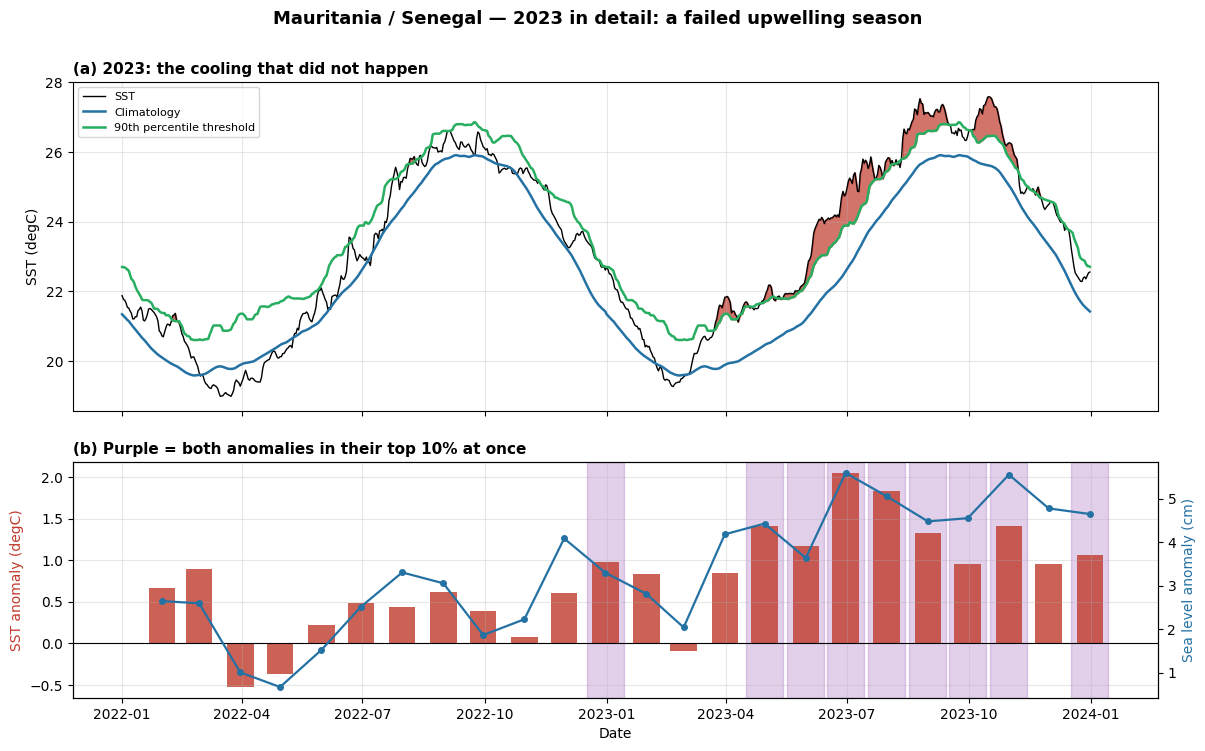

   COMPOUND MONTHS:
     2010-12   SST +1.88 degC   SLA +2.8 cm
     2022-12   SST +0.98 degC   SLA +3.3 cm
     2023-04   SST +1.41 degC   SLA +4.4 cm
     2023-05   SST +1.17 degC   SLA +3.6 cm
     2023-06   SST +2.05 degC   SLA +5.6 cm
     2023-07   SST +1.83 degC   SLA +5.1 cm
     2023-08   SST +1.33 degC   SLA +4.5 cm
     2023-09   SST +0.96 degC   SLA +4.5 cm
     2023-10   SST +1.41 degC   SLA +5.5 cm
     2023-12   SST +1.06 degC   SLA +4.6 cm

   THE SENTENCE FOR THE BRIEFING
   "In 2023 the upwelling season failed. From April to October the
    water was 1-2 degC warmer than normal and 4-6 cm higher, continuously,
    through the months when the fishery depends on cold, productive water.
    Nothing comparable occurred in the previous twelve years."


In [3]:
# ============================================================
# SCENARIO 1 — WORKED SOLUTION  (Mauritania / Senegal)
# ─────────────────────────────────────────────────────────────
# Produces the two briefing figures. Run before 14:15.
# ============================================================
import os, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


Z = ZONES['1']
print(f'{Z["name"]} — {Z["scenario"]}')
print(f'Audience: {Z["audience"]}\n')

print('Loading SST and SSH...')
sst_d = area_series('SST', 'analysed_sst', Z)
sla_d = area_series('SSH', 'sla', Z)
print('Done.\n')

# ---- seasonal cycle and its year-to-year spread ----
sst_m = sst_d.resample('ME').mean()
clim  = sst_m.groupby(sst_m.index.month).mean()
by_month_year = sst_m.groupby([sst_m.index.year, sst_m.index.month]).mean().unstack()

# ---- marine heatwaves ----
clim_s, p90_s = clim_and_threshold(sst_d)
doy = np.asarray(sst_d.index.dayofyear)
clim_line = pd.Series(doy, index=sst_d.index).map(clim_s)
p90_line  = pd.Series(doy, index=sst_d.index).map(p90_s)
ev, ev_idx = detect_mhw(sst_d, clim_line, p90_line)
above = (sst_d > p90_line)
days_by_year = above.groupby(above.index.year).sum()
worst = int(days_by_year.idxmax())

# ---- compound months ----
s_an = anomalies(sst_m)
l_m  = sla_d.resample('ME').mean()
l_an = anomalies(l_m)
idx  = s_an.index.intersection(l_an.index)
s_a, l_a = s_an.loc[idx], l_an.loc[idx]
both = (s_a > s_a.quantile(0.90)) & (l_a > l_a.quantile(0.90))
comp = idx[both]

print(f'   Marine heatwaves detected : {len(ev)}')
print(f'   Worst year                : {worst}, {int(days_by_year.max())} days '
      f'({100*days_by_year.max()/365:.0f}% of the year)')
print(f'   Compound months           : {len(comp)}')
print(f'   In {worst} alone              : {sum(t.year == worst for t in comp)}')
print()

# ============================ SLIDE 1 ============================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2),
                         gridspec_kw={'width_ratios':[1, 1.4]})

ax = axes[0]
for yr in range(2010, 2024):
    if yr in by_month_year.index:
        row = by_month_year.loc[yr]
        ax.plot(range(1,13), row.values, color='#95a5a6', lw=0.9, alpha=0.55)
ax.plot(range(1,13), clim.values, 'o-', color='black', lw=2.5, markersize=5,
        label='Climatology 2010-2023', zorder=5)
if worst in by_month_year.index:
    ax.plot(range(1,13), by_month_year.loc[worst].values, 'o-',
            color=Z['colour'], lw=2.5, markersize=5, label=str(worst), zorder=6)
ax.set_xticks(range(1,13)); ax.set_xticklabels([m[0] for m in MONTHS])
ax.set_xlabel('Month'); ax.set_ylabel('SST (degC)')
ax.set_title(f'(a) The upwelling season\neach grey line is one year',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

ax = axes[1]
cols = [Z['colour'] if y == worst else '#95a5a6' for y in days_by_year.index]
ax.bar(days_by_year.index, days_by_year.values, color=cols,
       edgecolor='black', linewidth=0.5)
ax.axhline(36.5, color='black', ls='--', lw=1)
ax.text(2010.2, 42, 'expected 10% of days', fontsize=8, color='black')
ax.set_xlabel('Year'); ax.set_ylabel('Days above the 90th percentile')
ax.set_title(f'(b) {worst} stands alone\n'
             f'{int(days_by_year.max())} days, {100*days_by_year.max()/365:.0f}% of the year',
             fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

fig.suptitle(f'{Z["name"]} — the upwelling season and how {worst} differed',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Key_S1_slide1.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================ SLIDE 2 ============================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                               gridspec_kw={'hspace':0.18,'height_ratios':[1.4,1]})

m = (sst_d.index.year >= worst-1) & (sst_d.index.year <= worst)
ax1.plot(sst_d.index[m], sst_d.values[m], color='black', lw=1.0, label='SST')
ax1.plot(clim_line.index[m], clim_line.values[m], color='#2471a3', lw=1.8,
         label='Climatology')
ax1.plot(p90_line.index[m], p90_line.values[m], color='#27ae60', lw=1.8,
         label='90th percentile threshold')
for a,b in ev_idx:
    if sst_d.index[a].year >= worst-1:
        ax1.fill_between(sst_d.index[a:b+1], p90_line.iloc[a:b+1],
                         sst_d.iloc[a:b+1], color=Z['colour'], alpha=0.7)
ax1.set_ylabel('SST (degC)')
ax1.set_title(f'(a) {worst}: the cooling that did not happen',
              fontsize=11, fontweight='bold', loc='left')
ax1.legend(fontsize=8, loc='upper left'); ax1.grid(True, alpha=0.3)

mm = (s_a.index.year >= worst-1) & (s_a.index.year <= worst)
ax2.bar(s_a.index[mm], s_a.values[mm], width=20, color='#c0392b',
        alpha=0.8, label='SST anomaly (degC)')
ax2b = ax2.twinx()
ax2b.plot(l_a.index[mm], l_a.values[mm]*100, 'o-', color='#2471a3',
          lw=1.6, markersize=4, label='Sea level anomaly (cm)')
for t in comp:
    if t.year >= worst-1:
        ax2.axvspan(t-pd.Timedelta(days=14), t+pd.Timedelta(days=14),
                    color='#8e44ad', alpha=0.25, zorder=0)
ax2.axhline(0, color='black', lw=0.8)
ax2.set_ylabel('SST anomaly (degC)', color='#c0392b')
ax2b.set_ylabel('Sea level anomaly (cm)', color='#2471a3')
ax2.set_xlabel('Date')
ax2.set_title('(b) Purple = both anomalies in their top 10% at once',
              fontsize=11, fontweight='bold', loc='left')
ax2.grid(True, alpha=0.3)

fig.suptitle(f'{Z["name"]} — {worst} in detail: a failed upwelling season',
             fontsize=13, fontweight='bold', y=0.97)
plt.savefig(f'{OUTPUT_DIR}/Key_S1_slide2.png', dpi=150, bbox_inches='tight')
plt.show()

print('   COMPOUND MONTHS:')
for t in comp:
    print(f'     {t:%Y-%m}   SST {s_a[t]:+.2f} degC   SLA {l_a[t]*100:+.1f} cm')
print()
print('   THE SENTENCE FOR THE BRIEFING')
print(f'   "In {worst} the upwelling season failed. From April to October the')
print('    water was 1-2 degC warmer than normal and 4-6 cm higher, continuously,')
print('    through the months when the fishery depends on cold, productive water.')
print('    Nothing comparable occurred in the previous twelve years."')


### Reading Scenario 1's figures

**Slide 1 (a)** — every grey line is one year folded onto a 12-month axis. The spread between them *is* the interannual variability. The red line is the worst year; where it sits clear of the grey envelope rather than merely at its edge, that is a departure no statistics are needed to see.

> **Check when the departure is largest.** In this area the coolest months are February–March, but 2023's anomaly peaks in **August–October**. So the seasonal minimum and the anomaly maximum do not coincide. That is worth asking the group about directly: *is the upwelling season later here than you assumed, or is something else driving the late-year warmth?* Either answer is a better briefing than assuming the two line up.

**Slide 1 (b)** — the dashed line marks what a 90th-percentile threshold gives by construction: about 36 days a year. A bar several times that height is the quantitative statement.

> **Do not let the group say "twelve quiet years then one bad one."** The record does not show that. **2010 has around 148 days** — high, and second only to the worst year — then a long quiet stretch, then a rise from 2020 peaking in 2023. The honest description is *a high year at the start, a decade of calm, and a recent upward trend*. If they claim an unprecedented event, ask them about 2010.
>
> Worth flagging that the first and last years of any record are the least well constrained, because the climatology has less surrounding data there. Whether 2010 is real or an edge effect is a legitimate question, and noticing it is a mark of a careful group.

**Slide 2 (a)** — the shaded excess should span months rather than appearing as brief spikes. Duration is the point: a long moderate departure does more than a short severe one, which is the same argument the Hobday cumulative-intensity metric makes.

**Slide 2 (b)** — the purple bands are compound months, where SST and sea level were both in their top 10%. Consecutive purple bands are the strongest single piece of evidence the group has, because they show a sustained state rather than a series of coincidences.

> **If a group asks whether they can blame the wind:** they can check. ERA5 is on the Drive. Weak alongshore wind through the anomalous months would turn their description into an explanation, and it is the natural extension if they finish early.

> **The limitation to insist on.** Their baseline is 14 years where the standard is 30, and it contains the very years they are calling anomalous. That makes their counts *conservative* — against an earlier baseline the anomaly would look larger, not smaller. A group that says this unprompted has understood the method.

---

---
---

#  Scenario 2 — Gulf of Guinea

**Audience:** Civil Protection Agency, Cotonou
**Brief:** coastal flooding is worsening along the Bight of Benin; which months carry the highest risk, and is that changing?

---

## What a strong briefing contains

| | |
|---|---|
| **The trend** | sea level rising, with a significance value, and total rise over the record |
| **The calendar** | which months are seasonally highest — the agency asked for a calendar, so give them one |
| **The compound windows** | two distinct clusters, November–December and May–July, meaning different things |
| **The action** | two watch periods, not a year-round warning |
| **The limitation** | altimetry degrades within 20–30 km of the coast — exactly where they need it |

## What to probe

- *"Your trend is in millimetres per year. What does that mean for Cotonou over ten years?"*
- *"You have two clusters of compound months. Are they the same kind of event?"*
- *"Civil Protection has to act on this. What do you actually want them to do in November?"*
- *"How much do you trust a satellite sea level measurement 10 km from the beach?"*

## Where groups go wrong

**Giving a trend without a calendar.** The agency asked which months. A trend alone does not answer it.

**Treating both clusters the same.** November–December is the seasonal warm peak. May–July is the upwelling season, so a compound event there means the cooling failed — a different signal with a different meaning.

**Overselling coastal altimetry.** The honest limitation is the one that makes the briefing trustworthy. Ask for it if it is missing.

---


Gulf of Guinea — Coastal flood risk calendar
Audience: Civil Protection Agency, Cotonou

Loading SST and SSH...
Done.

   Sea level trend : +5.08 mm/year
   p raw           : 2.94e-08
   p corrected     : 1.63e-06   (significant)
   Total rise      : +7.1 cm over 14 years

   Compound months : 7 of 168 (4.2%, expected 1%)
   SST-SLA r       : +0.73



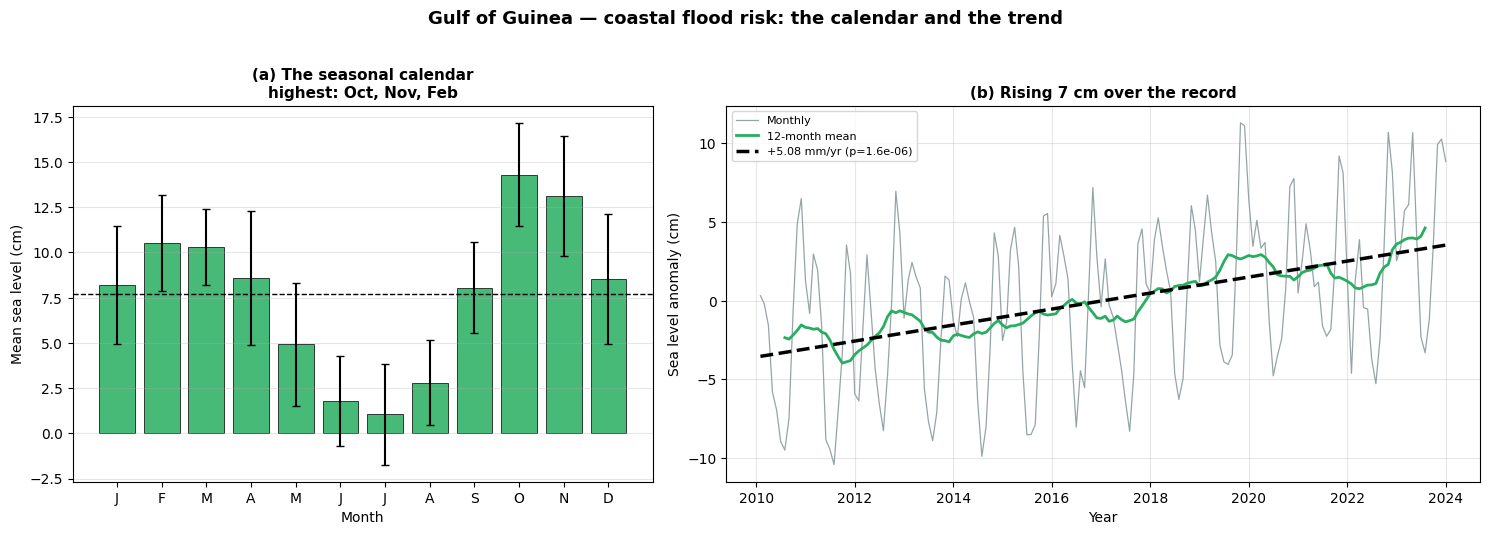

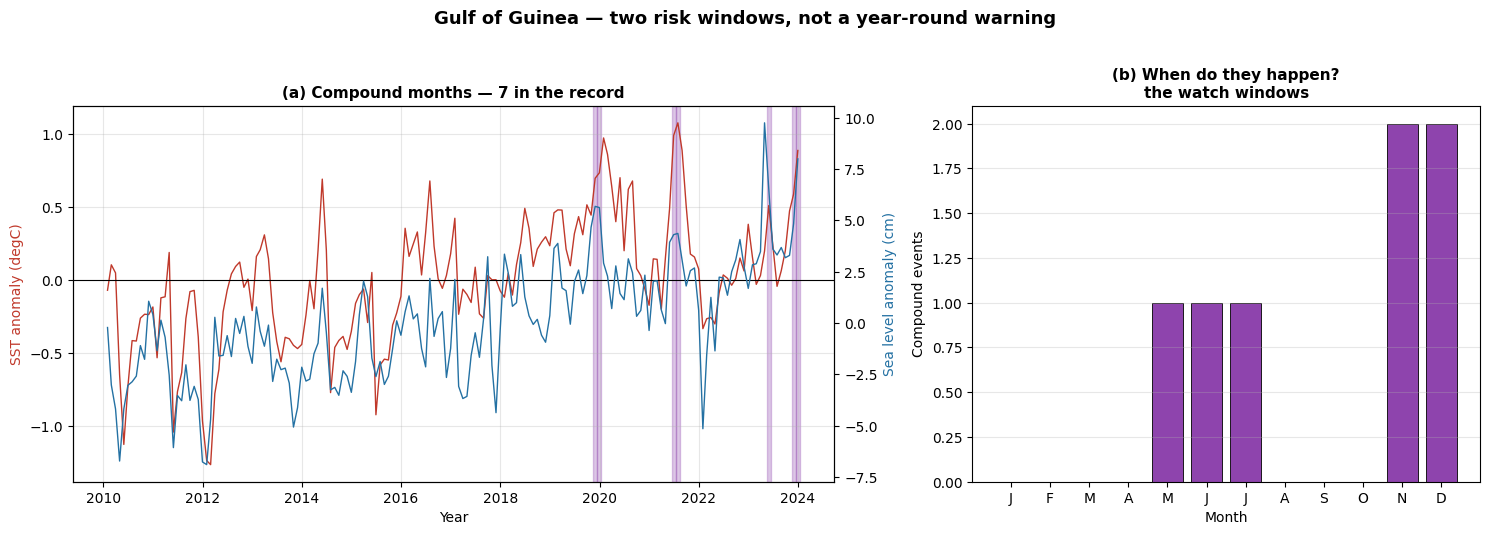

   COMPOUND MONTHS BY CALENDAR MONTH:
     May  #  (1)
     Jun  #  (1)
     Jul  #  (1)
     Nov  ##  (2)
     Dec  ##  (2)

   THE SENTENCE FOR THE BRIEFING
   "Sea level off this coast rose about 7 cm over 2010-2023.
    Compound conditions - unusually warm AND unusually high water -
    cluster in two windows. The late-year window is the seasonal peak.
    The mid-year window signals that the upwelling has not arrived.
    We recommend two watch periods rather than a year-round warning."

   THE LIMITATION TO STATE
   Altimetry degrades within 20-30 km of the coast. For Cotonou itself,
   a tide gauge is the reference, and this analysis is the offshore context.


In [4]:
# ============================================================
# SCENARIO 2 — WORKED SOLUTION  (Gulf of Guinea)
# ============================================================
import os, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


Z = ZONES['2']
print(f'{Z["name"]} — {Z["scenario"]}')
print(f'Audience: {Z["audience"]}\n')

print('Loading SST and SSH...')
sst_d2 = area_series('SST', 'analysed_sst', Z)
sla_d2 = area_series('SSH', 'sla', Z)
print('Done.\n')

sst_m2 = sst_d2.resample('ME').mean()
sla_m2 = sla_d2.resample('ME').mean()

# ---- sea level trend, autocorrelation-corrected ----
sl, p_raw, p_adj = trend_adj(sla_m2)
span = (sla_m2.index[-1]-sla_m2.index[0]).days/365.25
print(f'   Sea level trend : {sl*1000:+.2f} mm/year')
print(f'   p raw           : {p_raw:.3g}')
print(f'   p corrected     : {p_adj:.3g}   '
      f'({"significant" if p_adj<0.05 else "NOT significant"})')
print(f'   Total rise      : {sl*span*100:+.1f} cm over {span:.0f} years')
print()

# ---- seasonal calendar ----
sla_clim = sla_m2.groupby(sla_m2.index.month).mean()
sla_std  = sla_m2.groupby(sla_m2.index.month).std()

# ---- compound months ----
s_a2 = anomalies(sst_m2); l_a2 = anomalies(sla_m2)
idx2 = s_a2.index.intersection(l_a2.index)
s_b, l_b = s_a2.loc[idx2], l_a2.loc[idx2]
both2 = (s_b > s_b.quantile(0.90)) & (l_b > l_b.quantile(0.90))
comp2 = idx2[both2]
by_cal = pd.Series([t.month for t in comp2]).value_counts().sort_index()

print(f'   Compound months : {len(comp2)} of {len(idx2)} '
      f'({100*both2.mean():.1f}%, expected 1%)')
print(f'   SST-SLA r       : {stats.pearsonr(s_b.values, l_b.values)[0]:+.2f}')
print()

# ============================ SLIDE 1 ============================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2),
                         gridspec_kw={'width_ratios':[1, 1.3]})

ax = axes[0]
ax.bar(range(1,13), sla_clim.values*100, yerr=sla_std.values*100,
       color=Z['colour'], alpha=0.85, edgecolor='black', linewidth=0.6,
       capsize=3)
ax.axhline(sla_clim.mean()*100, color='black', ls='--', lw=1)
ax.set_xticks(range(1,13)); ax.set_xticklabels([m[0] for m in MONTHS])
ax.set_xlabel('Month'); ax.set_ylabel('Mean sea level (cm)')
hi = [MONTHS[m-1] for m in sla_clim.nlargest(3).index]
ax.set_title(f'(a) The seasonal calendar\nhighest: {", ".join(hi)}',
             fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
ax.plot(sla_m2.index, (sla_m2-sla_m2.mean()).values*100, color='#95a5a6',
        lw=0.9, label='Monthly')
roll = (sla_m2-sla_m2.mean()).rolling(12, center=True).mean()
ax.plot(roll.index, roll.values*100, color=Z['colour'], lw=2,
        label='12-month mean')
t = (sla_m2.index-sla_m2.index[0]).days/365.25
fit = stats.linregress(t, sla_m2.values)
ax.plot(sla_m2.index, (fit.intercept+fit.slope*t - sla_m2.mean())*100,
        color='black', lw=2.5, ls='--',
        label=f'{sl*1000:+.2f} mm/yr (p={p_adj:.2g})')
ax.set_xlabel('Year'); ax.set_ylabel('Sea level anomaly (cm)')
ax.set_title(f'(b) Rising {sl*span*100:.0f} cm over the record',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

fig.suptitle(f'{Z["name"]} — coastal flood risk: the calendar and the trend',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Key_S2_slide1.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================ SLIDE 2 ============================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2),
                         gridspec_kw={'width_ratios':[1.5, 1]})

ax = axes[0]
ax.plot(s_b.index, s_b.values, color='#c0392b', lw=1.0, label='SST anomaly (degC)')
axb = ax.twinx()
axb.plot(l_b.index, l_b.values*100, color='#2471a3', lw=1.0,
         label='Sea level anomaly (cm)')
for t0 in comp2:
    ax.axvspan(t0-pd.Timedelta(days=15), t0+pd.Timedelta(days=15),
               color='#8e44ad', alpha=0.3, zorder=0)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('SST anomaly (degC)', color='#c0392b')
axb.set_ylabel('Sea level anomaly (cm)', color='#2471a3')
ax.set_xlabel('Year')
ax.set_title(f'(a) Compound months — {len(comp2)} in the record',
             fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3)

ax = axes[1]
counts = [int(by_cal.get(m, 0)) for m in range(1,13)]
cols = ['#8e44ad' if c>0 else '#dfe6e9' for c in counts]
ax.bar(range(1,13), counts, color=cols, edgecolor='black', linewidth=0.6)
ax.set_xticks(range(1,13)); ax.set_xticklabels([m[0] for m in MONTHS])
ax.set_xlabel('Month'); ax.set_ylabel('Compound events')
ax.set_title('(b) When do they happen?\nthe watch windows',
             fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

fig.suptitle(f'{Z["name"]} — two risk windows, not a year-round warning',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Key_S2_slide2.png', dpi=150, bbox_inches='tight')
plt.show()

print('   COMPOUND MONTHS BY CALENDAR MONTH:')
for m in range(1,13):
    c = int(by_cal.get(m,0))
    if c: print(f'     {MONTHS[m-1]}  {"#"*c}  ({c})')
print()

# which months are seasonally highest, and where do the two lists overlap?
top3   = [m for m in sla_clim.nlargest(3).index]
low2   = [m for m in sla_clim.nsmallest(2).index]
comp_m = sorted(by_cal.index.tolist())
overlap = [m for m in comp_m if m in top3]
seasonal_range = (sla_clim.max() - sla_clim.min()) * 100
total_rise     = sl * span * 100
years = sorted({t.year for t in comp2})

print('   SEASONAL CALENDAR vs COMPOUND EVENTS — NOT THE SAME LIST')
print(f'     Seasonally highest : {", ".join(MONTHS[m-1] for m in top3)}')
print(f'     Seasonally lowest  : {", ".join(MONTHS[m-1] for m in low2)}')
print(f'     Compound months    : {", ".join(MONTHS[m-1] for m in comp_m)}')
if overlap:
    print(f'     BOTH               : {", ".join(MONTHS[m-1] for m in overlap)}'
          f'   <- the priority month(s)')
else:
    print('     BOTH               : none — worth asking the group why')
print()
print(f'     Seasonal range {seasonal_range:.0f} cm vs a trend of '
      f'{total_rise:.0f} cm over the record.')
print('     The month matters more than the decade, at least so far.')
print()

print('   THE SENTENCE FOR THE BRIEFING')
print(f'   "Sea level off this coast rose about {total_rise:.0f} cm over '
      f'{DATE_START[:4]}-{DATE_END[:4]}, and the')
print(f'    seasonal range is larger still - {seasonal_range:.0f} cm between the '
      f'{MONTHS[top3[0]-1]} peak and')
print(f'    the {MONTHS[low2[0]-1]} minimum. Compound conditions, unusually warm AND')
print(f'    unusually high water together, occurred {len(comp2)} times, all since')
print(f'    {min(years)}, in two windows. '
      + (f'{MONTHS[overlap[0]-1]} is the month that is both' if overlap
         else 'No month is both'))
print('    seasonally high and repeatedly anomalous, so it is the priority.')
print('    We recommend two watch periods rather than a year-round warning."')
print()

print('   THE SECOND WINDOW IS A DIFFERENT SIGNAL')
mid = [m for m in comp_m if m in low2 or 5 <= m <= 7]
if mid:
    print(f'   {", ".join(MONTHS[m-1] for m in mid)} is among the LOWEST sea level '
          'of the year. A compound')
    print('   event there is not high water in a high season - it means the')
    print('   upwelling failed and both variables went anomalous together.')
    print('   Treat it as an early warning that the season is not behaving,')
    print('   not as a flood risk in itself.')
print()

print('   THE LIMITATION TO STATE')
print('   Altimetry degrades within 20-30 km of the coast. For Cotonou itself,')
print('   a tide gauge is the reference, and this analysis is the offshore context.')

### Reading Scenario 2's figures

**Slide 1 (a)** — the seasonal calendar the agency asked for. Error bars are the year-to-year spread, so a month with a high mean *and* a large bar is both high and unpredictable, which is worse. October is the example: highest mean and one of the widest spreads.

> **The comparison that matters to a planner.** The seasonal range here is about **13 cm**, from the October peak to the July minimum. The trend over fourteen years is about **7 cm**. So the month you are in matters more than the decade — at least so far. That is the sentence a civil protection officer can act on.

**Slide 1 (b)** — the trend with its autocorrelation-corrected p-value. Groups often quote millimetres per year, which means little to an agency. **Push them to state the total rise over the record in centimetres**, and to say the p-value has been corrected — an uncorrected one would overstate the confidence.

**Slide 2 (a)** — every compound month falls in 2019 or later, none in the first decade. That is the temporal finding, and it is easy to miss on a busy plot. Make sure it reaches the briefing.

**Slide 2 (b)** — the histogram is the actionable output. Two clusters, and eight calendar months with nothing at all. That converts an analysis into a calendar.

> **The distinction to draw out, and it is not the obvious one.**
>
> The seasonally highest months are **October, November, February**. The compound clusters are **November–December** and **May–July**. Only **November** appears in both — which makes it the priority month, and the one clear answer the agency needs.
>
> October has the highest mean sea level of the year but produced *no* compound events, because SST is not unusual then. High water alone is not a compound event.
>
> May–July has the **lowest** sea level of the year, yet three compound events. When the upwelling fails in those months, both variables go anomalous together. So that cluster is not a flood risk in itself — it is an early warning that the season is not behaving.
>
> Same statistic, two different meanings, two different responses. A group that treats both clusters as "flood season" has missed the finding.

---

---
---

#  Scenario 3 — Agulhas

**Audience:** a national fisheries and oceans agency
**Brief:** aquaculture lost stock during a warm event; are these becoming more frequent, what drives them, and can they be anticipated?

---

## What a strong briefing contains

| | |
|---|---|
| **The puzzle** | the mildest heatwaves of the three areas, yet the largest sea level anomalies |
| **The evidence** | SST–sea level correlation of about 0.50 against 0.73 and 0.76 elsewhere |
| **The mechanism** | April 2020: SST anomaly only +0.6 degC, sea level +10.6 cm. Heat cannot explain that |
| **The confirmation** | an eddy snapshot for that month showing a ring in the domain |
| **The action** | monitor altimetry for approaching rings, not SST alone |

## What to probe

- *"Your compound events have the highest sea level of the three areas but the mildest warming. What does that tell you?"*
- *"If you monitored only SST, would you have seen April 2020 coming?"*
- *"An Agulhas ring travels a few kilometres a day. How much notice does that give?"*
- *"Where in your domain are the aquaculture sites, and how good is altimetry there?"*

## Where groups go wrong

**Framing it as a heatwave problem.** The card is deliberately about *risk*, not temperature. A group that only counts heatwaves will miss the finding.

**Not connecting to their own EKE map.** They made it this morning. Their compound events should sit in or near the high-EKE region, and checking that turns a correlation into a mechanism.

---


Agulhas — Eddy-driven coastal risk for aquaculture
Audience: A national fisheries and oceans agency

Loading SST and SSH...
Done.

   Compound months : 4
     2019-09   SST +0.86 degC   SLA +5.5 cm
     2020-04   SST +0.59 degC   SLA +10.6 cm
     2020-05   SST +0.79 degC   SLA +9.3 cm
     2020-06   SST +0.83 degC   SLA +4.5 cm
   SST-SLA r       : +0.50   (other areas ~ +0.73 and +0.76)

   THE PUZZLE MONTH: 2020-04
     SST anomaly +0.59 degC — modest
     SLA anomaly +10.6 cm — the largest of any area
     Thermal expansion cannot produce that. Something moved water in.



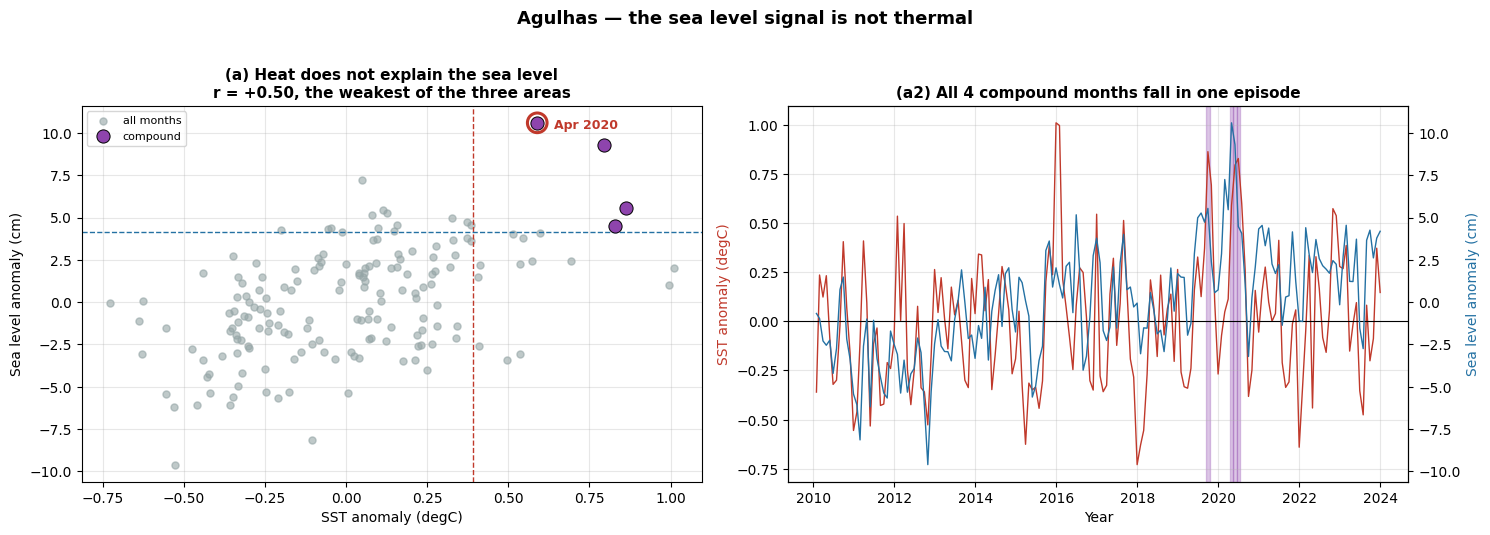

Building the eddy snapshot for 2020-04...


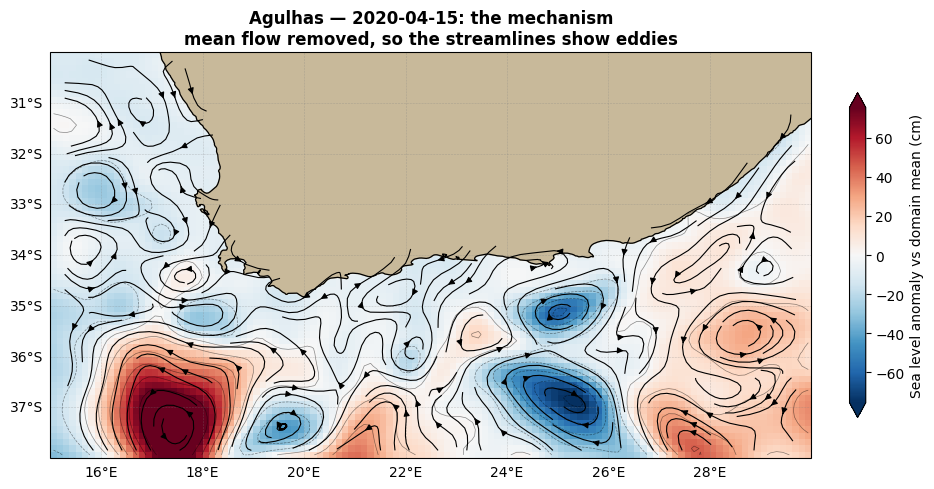

   SLA on 2020-04-15: -77.0 to +100.3 cm about the domain mean
   SLA on 2020-04-15, about the domain mean:
     strongest high : +100 cm      <- the ring core
     strongest low  : -77 cm
     98th percentile: 75 cm
     AREA MEAN      : +10.6 cm      <- what the compound test used

   TWO NUMBERS, BOTH TRUE, AND THE SECOND IS THE PERSUASIVE ONE.
   The compound test works on the area mean (+10.6 cm). An
   aquaculture operator experiences the LOCAL water level, and the
   ring core is +100 cm. Quote the area mean for the statistics
   and the local value for the impact.

   NOTE: a core above 60 cm is at the upper end of what Agulhas rings
   produce. Say so rather than presenting it flat - and remember that
   altimetry is least reliable near the coast, where the farms are.

   THE SENTENCE FOR THE BRIEFING
   "Our compound events carry the largest sea level anomalies of the
    three areas but the mildest warming, correlating at only +0.50
    against about +0.73 and +0.76 elsewher

In [6]:
# ============================================================
# SCENARIO 3 — WORKED SOLUTION  (Agulhas)
# ============================================================
import os, glob, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature


Z = ZONES['3']
print(f'{Z["name"]} — {Z["scenario"]}')
print(f'Audience: {Z["audience"]}\n')

print('Loading SST and SSH...')
sst_d3 = area_series('SST', 'analysed_sst', Z)
sla_d3 = area_series('SSH', 'sla', Z)
print('Done.\n')

sst_m3 = sst_d3.resample('ME').mean()
sla_m3 = sla_d3.resample('ME').mean()
s_a3, l_a3 = anomalies(sst_m3), anomalies(sla_m3)
idx3 = s_a3.index.intersection(l_a3.index)
s_c, l_c = s_a3.loc[idx3], l_a3.loc[idx3]
both3 = (s_c > s_c.quantile(0.90)) & (l_c > l_c.quantile(0.90))
comp3 = idx3[both3]
r3, p3 = stats.pearsonr(s_c.values, l_c.values)

print(f'   Compound months : {len(comp3)}')
for t in comp3:
    print(f'     {t:%Y-%m}   SST {s_c[t]:+.2f} degC   SLA {l_c[t]*100:+.1f} cm')
print(f'   SST-SLA r       : {r3:+.2f}   (other areas ~ +0.73 and +0.76)')
print()

# the month where sea level is high but SST is not — the puzzle
key = comp3[np.argmax([l_c[t] for t in comp3])]
print(f'   THE PUZZLE MONTH: {key:%Y-%m}')
print(f'     SST anomaly {s_c[key]:+.2f} degC — modest')
print(f'     SLA anomaly {l_c[key]*100:+.1f} cm — the largest of any area')
print('     Thermal expansion cannot produce that. Something moved water in.')
print()

# ============================ SLIDE 1 ============================
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

ax = axes[0]
ax.scatter(s_c.values, l_c.values*100, s=26, color='#95a5a6', alpha=0.6,
           label='all months')
ax.scatter([s_c[t] for t in comp3], [l_c[t]*100 for t in comp3], s=90,
           color='#8e44ad', edgecolor='black', linewidth=0.7, zorder=5,
           label='compound')
ax.scatter([s_c[key]], [l_c[key]*100], s=200, facecolor='none',
           edgecolor='#c0392b', linewidth=2.2, zorder=6)
ax.annotate(f'{key:%b %Y}', (s_c[key], l_c[key]*100),
            textcoords='offset points', xytext=(12,-4), fontsize=9,
            fontweight='bold', color='#c0392b')
ax.axvline(s_c.quantile(0.90), color='#c0392b', ls='--', lw=1)
ax.axhline(l_c.quantile(0.90)*100, color='#2471a3', ls='--', lw=1)
ax.set_xlabel('SST anomaly (degC)'); ax.set_ylabel('Sea level anomaly (cm)')
ax.set_title(f'(a) Heat does not explain the sea level\n'
             f'r = {r3:+.2f}, the weakest of the three areas',
             fontsize=11, fontweight='bold')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(s_c.index, s_c.values, color='#c0392b', lw=1.0, label='SST anomaly (degC)')
axb = ax.twinx()
axb.plot(l_c.index, l_c.values*100, color='#2471a3', lw=1.0,
         label='Sea level anomaly (cm)')
for t0 in comp3:
    ax.axvspan(t0-pd.Timedelta(days=15), t0+pd.Timedelta(days=15),
               color='#8e44ad', alpha=0.3, zorder=0)
ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel('SST anomaly (degC)', color='#c0392b')
axb.set_ylabel('Sea level anomaly (cm)', color='#2471a3')
ax.set_xlabel('Year')
ax.set_title(f'(a2) All {len(comp3)} compound months fall in one episode',
             fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3)

fig.suptitle(f'{Z["name"]} — the sea level signal is not thermal',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Key_S3_slide1.png', dpi=150, bbox_inches='tight')
plt.show()

# ============================ SLIDE 2: the mechanism ============================
print(f'Building the eddy snapshot for {key:%Y-%m}...')
ds_ssh = open_product('SSH', Z['prefix'])
ds_cur = open_product('CURR', Z['prefix'])
snap_date = f'{key:%Y-%m}-15'

sla_raw = clip_to(ds_ssh['sla'], Z).sel(time=snap_date, method='nearest').compute()
sla_c   = sla_raw - sla_raw.mean()
u_all = clip_to(surface(ds_cur['ugos']), Z)
v_all = clip_to(surface(ds_cur['vgos']), Z)
u_bar, v_bar = u_all.mean('time').compute(), v_all.mean('time').compute()
u_an = (u_all.sel(time=snap_date, method='nearest') - u_bar).compute()
v_an = (v_all.sel(time=snap_date, method='nearest') - v_bar).compute()
actual = str(sla_raw.time.values)[:10]

lim = max(float(abs(sla_c).quantile(0.98))*100, 1.0)
aspect = (Z['lon'][1]-Z['lon'][0])/(Z['lat'][1]-Z['lat'][0])
fig, ax = plt.subplots(figsize=(13, max(5.0, 13/aspect*0.6)),
                       subplot_kw={'projection': ccrs.PlateCarree()})
(sla_c*100).plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
                 vmin=-lim, vmax=lim, extend='both',
                 cbar_kwargs={'label':'Sea level anomaly vs domain mean (cm)',
                              'shrink':0.8,'pad':0.03},
                 add_labels=False, zorder=1)
cs = ax.contour(sla_c.longitude, sla_c.latitude, sla_c*100,
                levels=np.linspace(-lim, lim, 11), colors='black',
                linewidths=0.5, alpha=0.45,
                transform=ccrs.PlateCarree(), zorder=3)
us = u_an.sortby('latitude').sortby('longitude')
vs = v_an.sortby('latitude').sortby('longitude')
ax.streamplot(us.longitude.values, us.latitude.values,
              np.nan_to_num(us.values), np.nan_to_num(vs.values),
              transform=ccrs.PlateCarree(), density=1.8, linewidth=0.8,
              color='black', arrowsize=0.9, zorder=5)
ax.add_feature(cfeature.LAND, color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, zorder=4)
gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                  alpha=0.4, linestyle='--')
gl.top_labels=False; gl.right_labels=False
ax.set_title(f'{Z["name"]} — {actual}: the mechanism\n'
             f'mean flow removed, so the streamlines show eddies',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Key_S3_slide2.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'   SLA on {actual}: {float(sla_c.min())*100:+.1f} to '
      f'{float(sla_c.max())*100:+.1f} cm about the domain mean')
# ---- how strong is the eddy locally, not just in the area mean? ----
core_hi = float(sla_c.max()) * 100
core_lo = float(sla_c.min()) * 100
p98     = float(abs(sla_c).quantile(0.98)) * 100
area_mn = l_c[key] * 100

print(f'   SLA on {actual}, about the domain mean:')
print(f'     strongest high : {core_hi:+.0f} cm      <- the ring core')
print(f'     strongest low  : {core_lo:+.0f} cm')
print(f'     98th percentile: {p98:.0f} cm')
print(f'     AREA MEAN      : {area_mn:+.1f} cm      <- what the compound test used')
print()
print('   TWO NUMBERS, BOTH TRUE, AND THE SECOND IS THE PERSUASIVE ONE.')
print(f'   The compound test works on the area mean ({area_mn:+.1f} cm). An')
print(f'   aquaculture operator experiences the LOCAL water level, and the')
print(f'   ring core is {core_hi:+.0f} cm. Quote the area mean for the statistics')
print('   and the local value for the impact.')
print()
if core_hi > 60:
    print('   NOTE: a core above 60 cm is at the upper end of what Agulhas rings')
    print('   produce. Say so rather than presenting it flat - and remember that')
    print('   altimetry is least reliable near the coast, where the farms are.')
    print()

print('   THE SENTENCE FOR THE BRIEFING')
print('   "Our compound events carry the largest sea level anomalies of the')
print(f'    three areas but the mildest warming, correlating at only {r3:+.2f}')
print('    against about +0.73 and +0.76 elsewhere. In '
      f'{key:%B %Y} the area-mean')
print(f'    water level was {area_mn:.0f} cm high with an SST anomaly of only '
      f'{s_c[key]:+.1f} degC -')
print(f'    and the map shows why: a warm-core ring off the Cape with a core')
print(f'    {core_hi:.0f} cm above its surroundings. That is transport, not warming.')
print('    An early warning here must watch altimetry for approaching rings,')
print('    because temperature alone would not have seen it coming."')
print()

print('   THE OPERATIONAL QUESTION TO PUT TO THE GROUP')
print('   Agulhas rings travel roughly 5 km a day. Ask them: how far upstream')
print('   would a ring have to be for altimetry to give a useful warning?')
for km in [100, 300, 500]:
    print(f'     {km:>3} km upstream  ->  about {km/5/7:.0f} weeks notice')
print('   That is the number their audience actually needs, and it is the')
print('   difference between an analysis and an advisory.')
print()

print('   THE LIMITATION TO STATE')
print('   Altimetry degrades within 20-30 km of the coast - which is exactly')
print('   where the aquaculture sites are. This analysis is the offshore')
print('   context; the farm itself needs in-situ monitoring.')
ds_ssh.close(); ds_cur.close()


### Reading Scenario 3's figures

**Slide 1 (a)** — the scatter is the argument. The circled month sits well above the sea level threshold while barely clearing the SST one. Compare the vertical spread with the other two areas: here the sea level anomalies reach ±10 cm at almost any SST anomaly, whereas in the Gulf of Guinea and off Mauritania the two variables track each other much more tightly. That looser cloud *is* the weaker correlation, visible before any number is quoted.

**Slide 1 (a2)** — all four compound months fall in a single 2019–20 episode rather than spread across the record. That makes it an event to explain, not a trend to extrapolate — and it is a different shape from both other areas, which had events in three separate years and one seven-month block respectively.

**Slide 2** — the eddy snapshot with the mean flow removed. Look for a closed circulation, and check its sense: in the southern hemisphere an **anticyclone turns anticlockwise** around a high. A well-formed ring off the Cape with a core far above its surroundings is the mechanism demonstrated rather than inferred.

> **Two numbers, and the group needs both.** The compound test uses the **area mean**, which for April 2020 was about +11 cm. The map shows the **ring core** at several times that. Both are correct: the first is what the statistics are built on, the second is what an aquaculture site actually experiences. A briefing that quotes only the area mean understates the impact; one that quotes only the core overstates how widespread it was.

> **The honest caveat.** A ring core above 60 cm is at the upper end of what the Agulhas produces, and altimetry is least reliable within 20–30 km of the coast — which is exactly where the farms are. The offshore signal is solid; the value at the farm gate is not, and that is what in-situ monitoring is for.

> **The strongest thing this group can say:** the other two subgroups will describe warming-driven risk. Theirs is transport-driven, reached from the same two variables and the same method. That difference is the point of having three areas — and no group could have found it alone.

---

---
---

#  Running the Reconvergence Plenary

*15:45–16:30  ·  8–10 minutes per subgroup*

### The order to take them in

**Gulf of Guinea first.** The most conventional result — a trend and a calendar. It sets the pattern.

**Mauritania second.** Same method, but the finding is an *event* rather than a trend. It shows the method can find different kinds of thing.

**Agulhas last.** The mechanism is different from both. Ending here makes the closing synthesis land.

### Commentary to give each group

| Group | Praise | Push |
|---|---|---|
| **Gulf of Guinea** | turning a trend into a two-window calendar | did they state the coastal altimetry limitation? |
| **Mauritania** | recognising failure-to-cool rather than warming | did they check the wind? |
| **Agulhas** | reaching a different mechanism from the same data | how much warning would altimetry actually give? |

### The three questions that close the session

**1. Did any two of you find the same worst year?**
No — 2019, 2023 and 2020. So these were regional events with regional causes, and none of you could have known that alone.

**2. Your sea level trends are similar; your SST trends are not. Why?**
Most sea level rise is global — ice melt and deep-ocean expansion. Surface temperature is dominated by local variability. That is the argument for why operational systems lean so heavily on altimetry.

**3. You used the same two variables and the same method. Why three different mechanisms?**
Because the ocean differs. Thermal expansion in the Gulf of Guinea, upwelling failure off Mauritania, eddy transport in the Agulhas. **The method did not decide the answer — the physics did.**

---

### If a group is stuck at 14:45

The Coordinator checks engagement at 14:45. If a group has not started analysing:

- Give them the **one figure** from this key that matches their card, and ask them to interpret it rather than produce it. Interpretation is the harder and more valuable half.
- Or narrow the brief: *"Just answer which months, and why."*

A group that presents one figure well beats a group that presents four badly.

---

**End of the answer key**

*OPERA Advanced Interactive Activities (AIA) Set 1 · Facilitator material*
